In [2]:
pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 193.1 kB/s eta 0:00:0000:0100:02

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


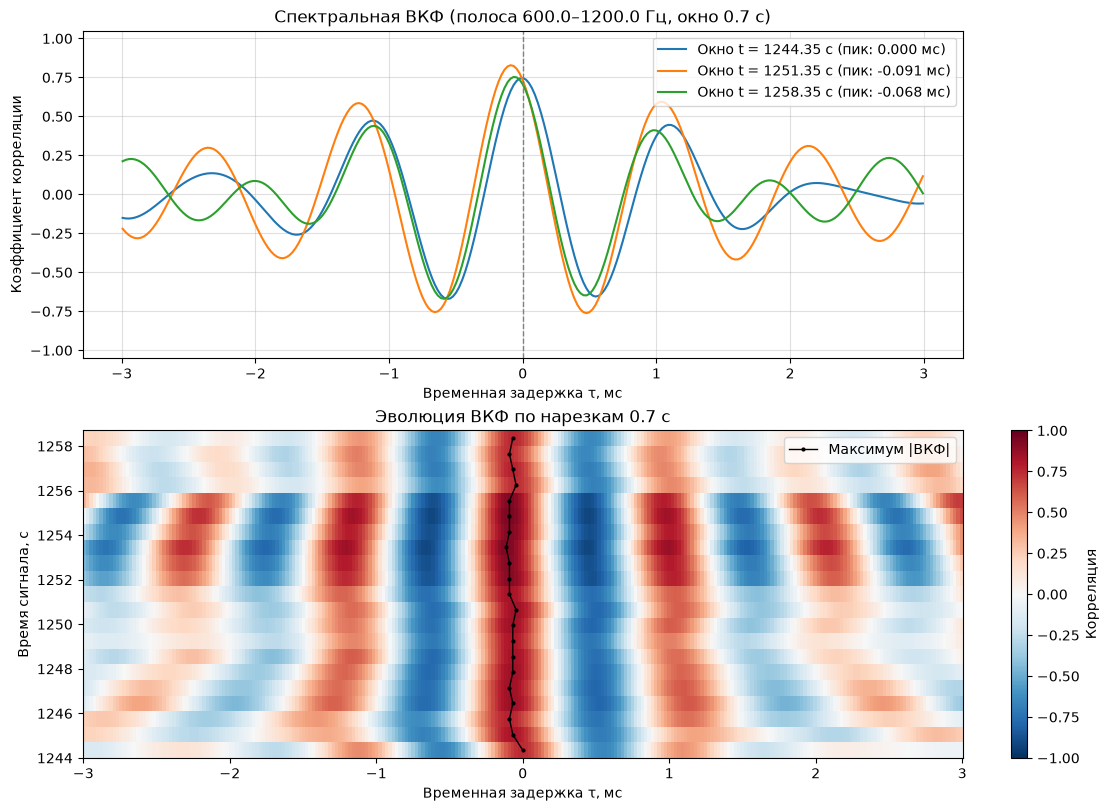

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt

# ==========================================
# 1. НАСТРОЙКИ ПОЛЬЗОВАТЕЛЯ
# ==========================================
# Пути к отдельным WAV-файлам для двух сравниваемых каналов
WAV_PATH_1 = '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S1.wav'
WAV_PATH_2 = '/Users/bogda/Documents/NFS/MSU/Кафедральные/6к11/Гидроакустические измерения/Пирамида/TASCAM_0035S2.wav'

# Путь к CSV с калибровкой (если параметры общие в одном файле)
CSV_PATH = None
CH_IDX_1 = 0  # Индекс строки в CSV для первого файла (0..3)
CH_IDX_2 = 1  # Индекс строки в CSV для второго файла (0..3)

# Выбранный диапазон времени для анализа (в секундах)
T_START = 1244.0                  # Начало анализируемого участка, сек
T_END = 1259.0                    # Конец анализируемого участка, сек

# Параметры нарезки
WINDOW_SEC = 0.7                 # Длина одного окна нарезки, сек
OVERLAP = 0.0                    # Перекрытие окон (0.0 = без перекрытия, 0.5 = 50%)

# Диапазон частот (полосовой фильтр), Гц
F_LOW = 600.0                    # Нижняя частота среза, Гц
F_HIGH = 1200.0                  # Верхняя частота среза, Гц

# Ограничение оси задержек на графике (в миллисекундах)
MAX_LAG_MS = 3.0                 

# ==========================================
# 2. ФУНКЦИИ ЗАГРУЗКИ, ВЫРАВНИВАНИЯ И КОРРЕЛЯЦИИ
# ==========================================
def load_single_channel(wav_path, csv_path=None, ch_idx=0):
    """Загружает моно-WAV, переводит во float, применяет Multiplier и Delay."""
    fs, data = wavfile.read(wav_path)
    
    # На случай если файл формально двухканальный, берем первый столбец
    if data.ndim > 1:
        data = data[:, 0]
        
    if np.issubdtype(data.dtype, np.integer):
        data = data.astype(np.float64) / np.iinfo(data.dtype).max
    else:
        data = data.astype(np.float64)
        
    if csv_path is not None:
        cal_df = pd.read_csv(csv_path)
        multiplier = float(cal_df["Multiplier"].iloc[ch_idx])
        delay_samples = int(cal_df["Delay"].iloc[ch_idx])
        
        data *= multiplier
        if delay_samples > 0:
            data = data[delay_samples:]
            
    return fs, data

def align_lengths_with_zeros(sig1, sig2, pad_left=False):
    """
    Выравнивает размерности двух массивов, дополняя более короткий нулями.
    По умолчанию дополняет справа (в конец), при pad_left=True — слева (в начало).
    """
    len1, len2 = len(sig1), len(sig2)
    if len1 == len2:
        return sig1, sig2
        
    diff = abs(len1 - len2)
    pad_width = (diff, 0) if pad_left else (0, diff)
    
    if len1 < len2:
        sig1 = np.pad(sig1, pad_width, mode='constant', constant_values=0.0)
    else:
        sig2 = np.pad(sig2, pad_width, mode='constant', constant_values=0.0)
        
    return sig1, sig2

def bandpass_filter(sig, fs, f_low, f_high, order=4):
    """Полосовой фильтр Баттерворта без фазовых искажений."""
    nyq = 0.5 * fs
    sos = butter(order, [f_low / nyq, f_high / nyq], btype='band', output='sos')
    return sosfiltfilt(sos, sig)

def spectral_xcorr(x, y):
    """
    Вычисляет нормированную линейную взаимно-корреляционную функцию
    через произведение спектров: IFFT(FFT(x) * conj(FFT(y))).
    """
    # Выравниваем длины нулями, если вдруг переданы массивы разной длины
    x, y = align_lengths_with_zeros(x, y, pad_left=False)
    n = len(x)
    
    # 1. Убираем среднее значение в каждом сигнале
    x = x - np.mean(x)
    y = y - np.mean(y)
    
    # 2. Дополняем нулями до 2*N - 1 (или ближайшей степени двойки >= 2*N - 1),
    #    чтобы избежать циклической свертки при перемножении спектров
    n_fft = 1 << (2 * n - 1).bit_length()
    
    spec_x = np.fft.rfft(x, n=n_fft)
    spec_y = np.fft.rfft(y, n=n_fft)
    
    # 3. Произведение спектров (кросс-спектр) и обратное БПФ
    cross_spectrum = spec_x * np.conj(spec_y)
    ccf_raw = np.fft.irfft(cross_spectrum, n=n_fft)
    
    # 4. Переставляем отрицательные и положительные задержки в стандартный порядок:
    #    от -(N-1) до +(N-1)
    ccf_linear = np.concatenate((ccf_raw[-(n - 1):], ccf_raw[:n]))
    
    # 5. Нормировка на энергию сигналов в окне [-1, 1]
    norm = np.sqrt(np.sum(x**2) * np.sum(y**2))
    if norm > 0:
        ccf_linear /= norm
    else:
        ccf_linear = np.zeros_like(ccf_linear)
        
    lags = np.arange(-(n - 1), n)
    return ccf_linear, lags

# ==========================================
# 3. ЗАГРУЗКА И ПРЕДОБРАБОТКА ДАННЫХ
# ==========================================
fs1, raw_sig1 = load_single_channel(WAV_PATH_1, CSV_PATH, CH_IDX_1)
fs2, raw_sig2 = load_single_channel(WAV_PATH_2, CSV_PATH, CH_IDX_2)

if fs1 != fs2:
    raise ValueError(f"Частоты дискретизации файлов не совпадают: {fs1} Гц и {fs2} Гц!")
fs = fs1

# Выравниваем общую длину записей нулями справа, если один файл короче другого
raw_sig1, raw_sig2 = align_lengths_with_zeros(raw_sig1, raw_sig2, pad_left=False)

# Фильтрация с небольшим запасом по краям, чтобы избежать краевых эффектов фильтра
pad_sec = 0.5
idx_start_pad = max(0, int((T_START - pad_sec) * fs))
idx_end_pad = min(len(raw_sig1), int((T_END + pad_sec) * fs))

filt1 = bandpass_filter(raw_sig1[idx_start_pad:idx_end_pad], fs, F_LOW, F_HIGH)
filt2 = bandpass_filter(raw_sig2[idx_start_pad:idx_end_pad], fs, F_LOW, F_HIGH)

# Вырезаем строго выбранный диапазон [T_START, T_END]
trim_start = int(T_START * fs) - idx_start_pad
trim_end = trim_start + int((T_END - T_START) * fs)

sig1 = filt1[trim_start:trim_end]
sig2 = filt2[trim_start:trim_end]

# Если запрос T_END вышел за границу файла, добиваем недостающий хвост нулями
target_len = int((T_END - T_START) * fs)
if len(sig1) < target_len:
    sig1 = np.pad(sig1, (0, target_len - len(sig1)), mode='constant')
if len(sig2) < target_len:
    sig2 = np.pad(sig2, (0, target_len - len(sig2)), mode='constant')

# ==========================================
# 4. НАРЕЗКА ПО 0.7 СЕК И РАСЧЕТ ВКФ ЧЕРЕЗ СПЕКТРЫ
# ==========================================
win_samples = int(round(WINDOW_SEC * fs))
step_samples = int(round(win_samples * (1.0 - OVERLAP)))

ccf_matrix = []
window_times = []
peak_delays_ms = []
lags_ms_zoom = None

for start in range(0, len(sig1) - win_samples + 1, step_samples):
    w1 = sig1[start : start + win_samples]
    w2 = sig2[start : start + win_samples]
    
    # Расчет ВКФ через произведение спектров (с вычитанием среднего внутри)
    ccf, lags = spectral_xcorr(w1, w2)
    
    if lags_ms_zoom is None:
        lags_ms = (lags / fs) * 1000.0
        lag_mask = (lags_ms >= -MAX_LAG_MS) & (lags_ms <= MAX_LAG_MS)
        lags_ms_zoom = lags_ms[lag_mask]
        
    ccf_zoom = ccf[lag_mask]
    ccf_matrix.append(ccf_zoom)
    
    t_center = T_START + (start + win_samples / 2) / fs
    window_times.append(t_center)
    
    best_lag = lags_ms_zoom[np.argmax(np.abs(ccf_zoom))]
    peak_delays_ms.append(best_lag)

ccf_matrix = np.array(ccf_matrix)

# ==========================================
# 5. ВИЗУАЛИЗАЦИЯ
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)

indices_to_plot = [0, len(ccf_matrix) // 2, len(ccf_matrix) - 1]
for idx in sorted(set(indices_to_plot)):
    axes[0].plot(
        lags_ms_zoom, 
        ccf_matrix[idx], 
        label=f"Окно t = {window_times[idx]:.2f} с (пик: {peak_delays_ms[idx]:.3f} мс)"
    )

axes[0].axvline(0, color='gray', linestyle='--', linewidth=1)
axes[0].set_title(f"Спектральная ВКФ (полоса {F_LOW}–{F_HIGH} Гц, окно {WINDOW_SEC} с)")
axes[0].set_xlabel("Временная задержка τ, мс")
axes[0].set_ylabel("Коэффициент корреляции")
axes[0].set_ylim(-1.05, 1.05)
axes[0].grid(True, alpha=0.4)
axes[0].legend(loc="upper right")

im = axes[1].pcolormesh(
    lags_ms_zoom, 
    window_times, 
    ccf_matrix, 
    shading='auto', 
    cmap='RdBu_r', 
    vmin=-1, 
    vmax=1
)
axes[1].plot(peak_delays_ms, window_times, 'k.-', linewidth=1, markersize=4, label="Максимум |ВКФ|")
axes[1].set_title("Эволюция ВКФ по нарезкам 0.7 с")
axes[1].set_xlabel("Временная задержка τ, мс")
axes[1].set_ylabel("Время сигнала, с")
axes[1].legend(loc="upper right")
fig.colorbar(im, ax=axes[1], label="Корреляция")

plt.show()